In [138]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss, plot_mae, evaluate_model, plot_loss_and_mae

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import tensorflow as tf

<h1> Import Data

Text(0.5, 0.98, 'All Data')

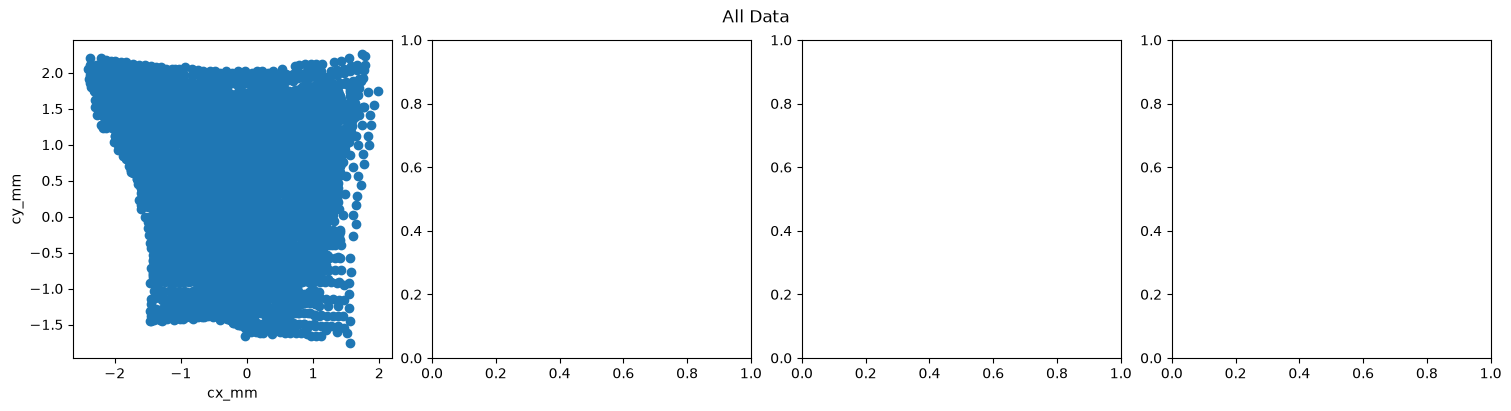

In [139]:
data_3 = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_list = [data_3]

fig, axs = plt.subplots(1, 4, figsize=(15,4), constrained_layout=True)
for i, data in enumerate(data_list):
    subplot = axs[i]
    subplot.scatter(data["cx_mm"], data["cy_mm"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
fig.suptitle("All Data")

<h2> Remove NaNs

In [140]:
all_data = data_3.dropna()

data_3.Name = "data_3"

<h2> Create StandardScalers based on all data

In [141]:
scalerX = StandardScaler().fit(all_data[["cx_mm", "cy_mm"]])
scalerY = StandardScaler().fit(all_data[["s0", "s1", "s2"]])

<h2>Scale all datasets

In [142]:
X_scaled = scalerX.transform(all_data[["cx_mm", "cy_mm"]])
y_scaled = scalerY.transform(all_data[["s0", "s1", "s2"]])

<h2> Build Model

In [143]:
model = build_nn_model(X_scaled.shape[1], y_scaled.shape[1])
model.summary() #investigate

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_44 (Dense)                │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,531 (25.51 KB)

 Trainable params: 6,531 (25.51 KB)

 Non-trainable params: 0 (0.00 B)

<h1> Training on data_1 - 16thOct

<h2>TimeSeriesSplit

In [144]:
def plot_motors(y_test, y_pred, lims): 
    fig, axs = plt.subplots(1, 3)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()

Fold 0:
  Train: index=0 to 993 
  Test:  index=994 to 1984

Fold: 0 Results (scaled):
  Overall R2:  0.8502
  Weighted R2: 0.8623
Fold 1:
  Train: index=0 to 1984 
  Test:  index=1985 to 2975

Fold: 1 Results (scaled):
  Overall R2:  0.7962
  Weighted R2: 0.8019
Fold 2:
  Train: index=0 to 2975 
  Test:  index=2976 to 3966

Fold: 2 Results (scaled):
  Overall R2:  0.8255
  Weighted R2: 0.8463
MSE scores for each fold: [0.09004440903663635, 0.1442541629076004, 0.13687287271022797]


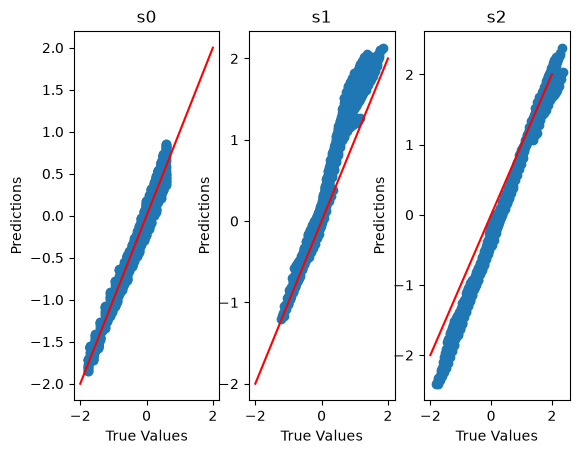

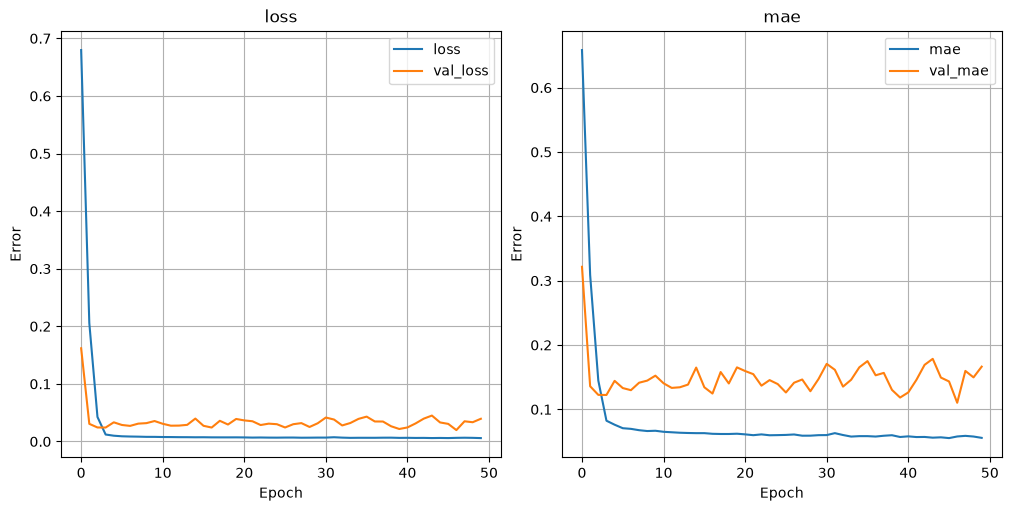

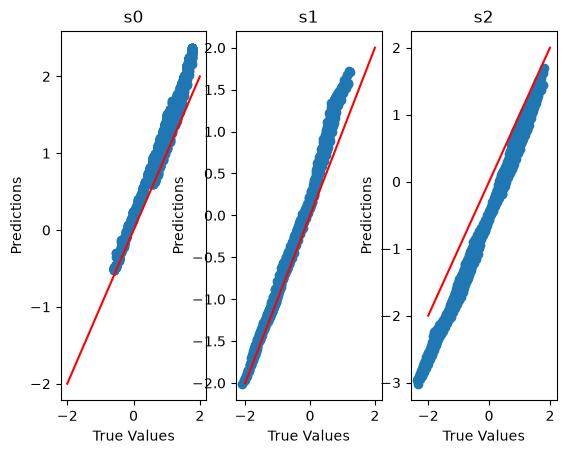

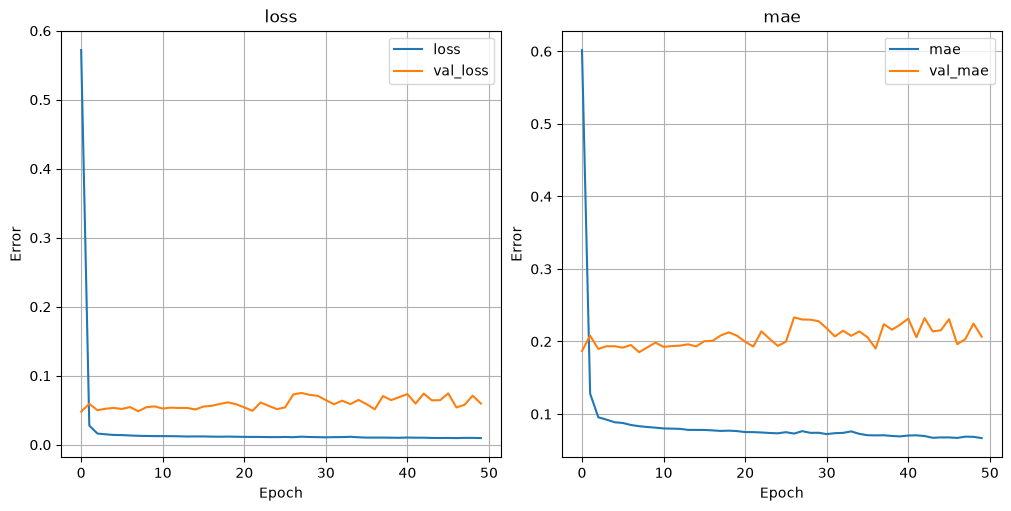

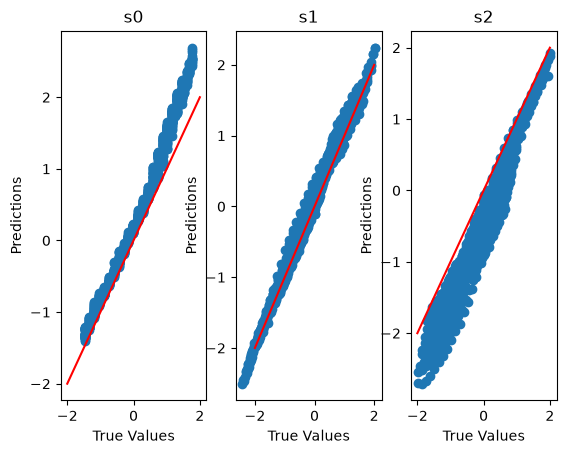

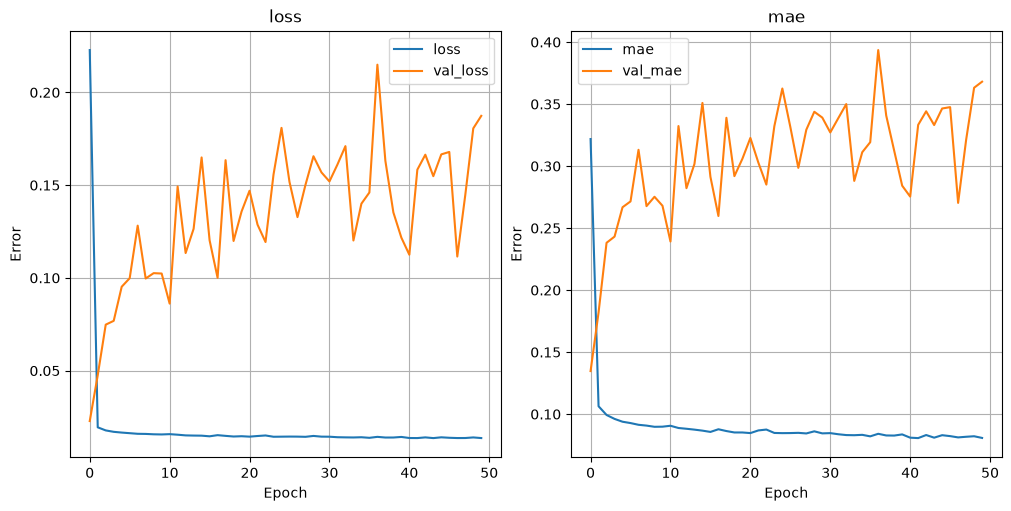

In [151]:
scores = []

X = X_scaled
y = y_scaled

tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = build_nn_model(X_scaled.shape[1], y_scaled.shape[1]) #instantiate new model each time to see difference

    history = train_model(model, X_train, y_train, verbose=0, epochs=50)
    y_pred = model.predict(X_test, verbose=0)

    evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)
    plot_motors(y_test, y_pred, [-2,2])

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plot_loss_and_mae(history)

print("MSE scores for each fold:", scores)

In [146]:
y_pred_inverse = scalerY.inverse_transform(y_pred)
y_test_inverse = scalerY.inverse_transform(y_test)

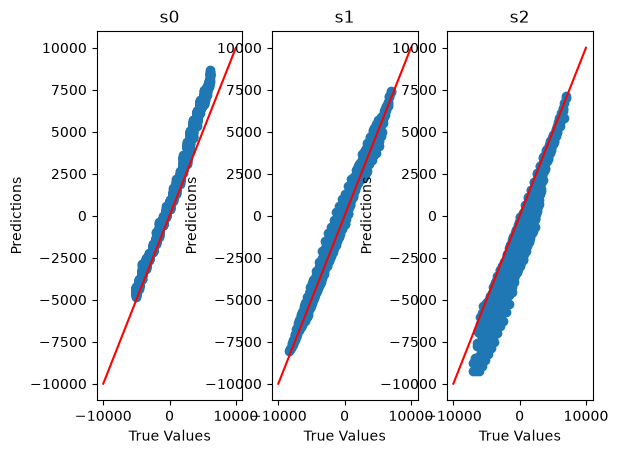

In [147]:
plot_motors(y_test_inverse, y_pred_inverse, [-10000,10000])

In [148]:
y_pred_df = pd.DataFrame(y_pred_inverse)

y_pred_df["s0_true"] = y_test_inverse[:,0]
y_pred_df["s1_true"] = y_test_inverse[:,1]
y_pred_df["s2_true"] = y_test_inverse[:,2]

y_pred_df["s0_diff"] = y_pred_df["s0_true"] - y_pred_df[0]
y_pred_df["s1_diff"] = y_pred_df["s1_true"] - y_pred_df[1]
y_pred_df["s2_diff"] = y_pred_df["s2_true"] - y_pred_df[2]

y_pred_df

,0,1,2,s0_true,s1_true,s2_true,s0_diff,s1_diff,s2_diff
0,5530.949219,-3457.677002,-2019.425659,4095.999756,-3821.000244,-275.0,-1434.949463,-363.323242,1744.425659
1,5678.823242,-3638.835693,-1989.378296,4095.999756,-4043.000000,-53.0,-1582.823486,-404.164307,1936.378296
2,5750.127441,-3910.368164,-1777.451050,4095.999756,-4265.000000,169.0,-1654.127686,-354.631836,1946.451050
3,5662.459961,-4056.264648,-1540.208252,4095.999756,-4486.000000,390.0,-1566.460205,-429.735352,1930.208252
4,5650.158691,-4264.805176,-1319.503418,4095.999756,-4708.000000,612.0,-1554.158936,-443.194824,1931.503418
...,...,...,...,...,...,...,...,...,...
986,7371.024902,-6387.336426,-1059.605591,5120.000000,-6994.000000,1874.0,-2251.024902,-606.663574,2933.605469
987,788.644348,-136.872360,-557.510254,0.000000,0.000000,0.0,-788.644348,136.872360,557.510254
988,788.644348,-136.872360,-557.510254,0.000000,0.000000,0.0,-788.644348,136.872360,557.510254
989,788.644348,-136.872360,-557.510254,0.000000,0.000000,0.0,-788.644348,136.872360,557.510254


In [149]:
y_pred_df.index[y_pred_df["s1_diff"] == max(y_pred_df["s1_diff"])]

RangeIndex(start=519, stop=520, step=1)

In [150]:
y_pred_df.index[y_pred_df["s2_diff"] == max(y_pred_df["s2_diff"])]

RangeIndex(start=976, stop=977, step=1)